# Задача 4.4
# Повтор стороны симметричной монеты

## Условие
Симметричную монету бросают до первого повторения одной и той же стороны подряд. Построить модель $(\Omega,P)$ и найти вероятность чётного числа бросков.

## Теория с нуля и решение вручную

### 1. Вероятностная модель остановленного опыта
Обозначим герб буквой $Г$, решку — $Р$. $T$ — номер броска, на котором впервые появились два одинаковых результата подряд. Минимум $T=2$. До последних двух символов последовательность обязана чередоваться. Для каждого $k\ge2$ есть ровно две допустимые остановленные строки длины $k$: начинающаяся с $Г$ и начинающаяся с $Р$. Например, при $k=4$ это $ГРГГ$ и $РГРР$.

$\Omega$ — множество всех таких конечных строк. Для строки $\omega$ с $h$ гербами и $r$ решками определяем $P(\{\omega\})=p^h(1-p)^r$. Для любого события $E\subseteq\Omega$ вероятности его строк складываем: $P(E)=\sum_{\omega\in E}P(\{\omega\})$. При $0<p<1$ бесконечное чередование имеет вероятность ноль, поэтому сумма вероятностей конечных остановок равна 1. Если хочется включить бесконечные чередующиеся строки в пространство, каждой приписываем нулевую вероятность.

### 2. Распределение момента остановки
Положим $q=1-p$, $r=pq$. Для $T=2m$ две строки имеют вероятности $p^{m+1}q^{m-1}$ и $q^{m+1}p^{m-1}$. Для $T=2m+1$ обе строки содержат одну сторону $m+1$ раз, другую $m$ раз:
$$P(T=2m)=(p^2+q^2)r^{m-1},\qquad P(T=2m+1)=r^m,\qquad m\ge1.$$
Сумма этих вероятностей по всем $m$ равна $(p^2+q^2+r)/(1-r)=1$, поскольку $p^2+q^2=1-2r$. Это проверка вероятностной модели.

### 3. Геометрический ряд
При $|z|<1$ имеем $1+z+z^2+\cdots=1/(1-z)$. Это следует из вычитания $zS$ из $S$: остаётся $1$. Если нужны только чётные значения $T$, складываем вероятности $T=2,4,6,\ldots$.

### 4. Ответ для симметричной монеты
При $p=q=1/2$ обе строки длины $k$ имеют вероятность $2^{-k}$, поэтому
$$P(T=k)=2^{1-k},\qquad k\ge2.$$
Чётные остановки образуют ряд:
$$P(T\text{ чётно})=\frac12+\frac18+\frac1{32}+\cdots=\frac{1/2}{1-1/4}=\frac23.$$
Здесь отношение соседних членов $1/4$, потому что от одной чётной длины до следующей добавляются два броска. Нельзя считать чётность равновероятной: уже остановка на втором броске имеет вероятность $1/2$.

### 5. Переход к коду
Запоминаем предыдущую сторону, затем бросаем следующую. При совпадении останавливаемся; иначе обновляем предыдущую. Остаток `T % 2` равен нулю ровно для чётных чисел.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Чётное число бросков: успехов 99804, знаменатель 150000
  частота = 0.66536000; ориентир 95%: [0.66297204; 0.66774796]
  теория = 0.66666667; разность = -0.00130667


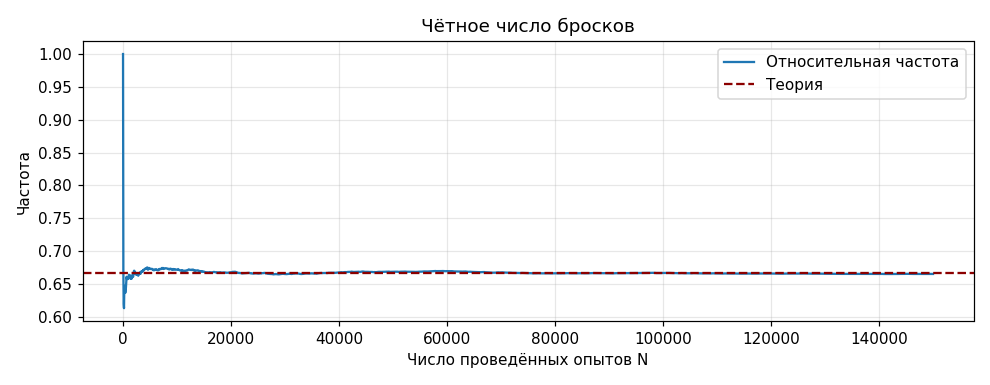

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
T = np.zeros(N, dtype=int)
for i in range(N):
    previous = rng.random() < 0.5
    t = 1
    while True:
        current = rng.random() < 0.5
        t += 1
        if current == previous:
            break
        previous = current
    T[i] = t
report(T % 2 == 0, 'Чётное число бросков', Fraction(2, 3))
